# Tuần 1 · Dự đoán khả năng mua hàng trên website

Mỗi dòng là một phiên truy cập. Nhãn `Revenue=True` biểu thị phiên kết thúc bằng giao dịch mua hàng. Tuần này kiểm tra dữ liệu, chia train/test và khảo sát tập train. Tập test được giữ cho đánh giá cuối ở tuần 3.

Nguồn CSV [Sakar & Kastro (2018), UCI Machine Learning Repository, CC BY 4.0](https://doi.org/10.24432/C5F88Q). Trong VS Code, mở thư mục gốc của project và chọn kernel Python từ `.venv`.

## 1. Kiểm tra dữ liệu gốc

In [1]:
%matplotlib inline

from hashlib import sha256
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split

csv_name = "online_shoppers_intention.csv"
csv_path = Path("data") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)
if not csv_path.is_file():
    raise FileNotFoundError(f"Hãy đặt CSV tại data/{csv_name} trong thư mục gốc project.")

df = pd.read_csv(csv_path)
print(f"CSV: {csv_path.as_posix()}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
display(pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số giá trị thiếu": df.isna().sum(),
}))
print(f"Tổng số giá trị thiếu: {df.isna().sum().sum()}")
print(f"Số dòng trùng hoàn toàn, tính từ lần xuất hiện thứ hai: {df.duplicated().sum()}")

label_names = {False: "Không mua", True: "Có mua"}
counts = df["Revenue"].value_counts().reindex([False, True])
display(pd.DataFrame({
    "Số phiên": counts,
    "Tỷ lệ": (counts / len(df)).map("{:.2%}".format),
}).rename(index=label_names).rename_axis("Revenue"))

CSV: data/online_shoppers_intention.csv
Kích thước: 12,330 dòng × 18 cột


,Kiểu dữ liệu,Số giá trị thiếu
Administrative,int64,0
Administrative_Duration,float64,0
Informational,int64,0
Informational_Duration,float64,0
ProductRelated,int64,0
ProductRelated_Duration,float64,0
BounceRates,float64,0
ExitRates,float64,0
PageValues,float64,0
SpecialDay,float64,0


Tổng số giá trị thiếu: 0
Số dòng trùng hoàn toàn, tính từ lần xuất hiện thứ hai: 125


,Số phiên,Tỷ lệ
Revenue,,
Không mua,10422,84.53%
Có mua,1908,15.47%


`OperatingSystems`, `Browser`, `Region` và `TrafficType` là mã phân loại. Các số chỉ định nhóm và không có ý nghĩa về thứ tự hay khoảng cách. `Month`, `VisitorType` và `Weekend` cũng là biến phân loại. `ProductRelated` là biến đếm rời rạc và `ProductRelated_Duration` là biến định lượng liên tục.

Giữ các dòng trùng hoàn toàn vì hai phiên khác nhau có thể có cùng bộ giá trị tổng hợp. CSV không có mã phiên để xác định chúng có phải cùng một phiên hay không.

## 2. Chia train/test có phân tầng

Tách `Revenue` làm nhãn và bỏ `PageValues` khỏi bộ feature chính theo kế hoạch đồ án. Lần chạy đầu lưu vị trí dòng theo thứ tự của từng tập vào `data/split_indices.json`. Các lần chạy sau đọc lại các vị trí đã lưu bằng `.iloc`. SHA-256 giúp kiểm tra CSV có còn đúng nội dung và thứ tự dòng khi split được tạo hay không.

In [2]:
y = df["Revenue"]
X = df.drop(columns=["Revenue", "PageValues"])

split_path = Path("data/split_indices.json")
split_metadata = {
    "csv_sha256": sha256(csv_path.read_bytes()).hexdigest(),
    "n_rows": len(df),
    "test_size": 0.2,
    "random_state": 42,
    "stratify": "Revenue",
}
split_exists = split_path.is_file()

if split_exists:
    split = json.loads(split_path.read_text(encoding="utf-8"))
    if any(split[key] != value for key, value in split_metadata.items()):
        raise ValueError("CSV hoặc cấu hình chia tập đã thay đổi. Hãy kiểm tra lại split đã lưu.")
    train_indices = split["train_indices"]
    test_indices = split["test_indices"]
else:
    train_indices, test_indices = train_test_split(
        df.index.tolist(), test_size=0.2, random_state=42, stratify=y
    )

all_indices = train_indices + test_indices
if (
    any(type(index) is not int for index in all_indices)
    or len(all_indices) != len(df)
    or set(all_indices) != set(df.index)
):
    raise ValueError("Split phải chứa đủ vị trí dòng và mỗi vị trí chỉ xuất hiện một lần.")

X_train, y_train = X.iloc[train_indices], y.iloc[train_indices]
X_test, y_test = X.iloc[test_indices], y.iloc[test_indices]
overlap = X_train.index.intersection(X_test.index)
assert len(overlap) == 0
assert X_train.index.is_unique and X_test.index.is_unique
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

if split_exists:
    print(f"Đã đọc split từ {split_path.as_posix()}")
else:
    split = {
        **split_metadata,
        "train_indices": train_indices,
        "test_indices": test_indices,
    }
    split_path.parent.mkdir(parents=True, exist_ok=True)
    split_path.write_text(json.dumps(split, indent=2) + "\n", encoding="utf-8")
    print(f"Đã lưu split vào {split_path.as_posix()}")

display(pd.DataFrame({
    "Số phiên": [len(y_train), len(y_test)],
    "Không mua": [(~y_train).sum(), (~y_test).sum()],
    "Có mua": [y_train.sum(), y_test.sum()],
    "Tỷ lệ mua": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
}, index=["Train", "Test"]))
print(f"Số feature: {X_train.shape[1]}")
print(f"Số index chung: {len(overlap)}")

Đã đọc split từ data/split_indices.json


,Số phiên,Không mua,Có mua,Tỷ lệ mua
Train,9864,8338,1526,15.47%
Test,2466,2084,382,15.49%


Số feature: 16
Số index chung: 0


## 3. Phân bố trên tập train

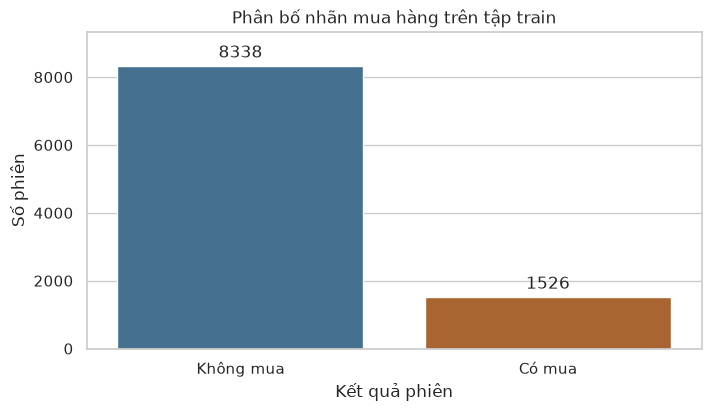

In [3]:
sns.set_theme(style="whitegrid", font="DejaVu Sans")
train = X_train.assign(Revenue=y_train, KetQua=y_train.map(label_names))
label_order = list(label_names.values())
palette = {"Không mua": "#39729C", "Có mua": "#BC621D"}

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.countplot(data=train, x="KetQua", order=label_order, hue="KetQua",
              palette=palette, legend=False, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set(title="Phân bố nhãn mua hàng trên tập train",
       xlabel="Kết quả phiên", ylabel="Số phiên")
ax.margins(y=0.12)
plt.show()

Hai biểu đồ sau dùng hàm phân phối tích lũy thực nghiệm (ECDF). Tại mỗi giá trị trên trục ngang, đường biểu diễn cho biết tỷ lệ phiên trong nhóm có giá trị nhỏ hơn hoặc bằng mức đó. Mỗi nhóm có mẫu số riêng. Thang symlog trên trục ngang giữ giá trị 0 và giúp quan sát phần đuôi dài.

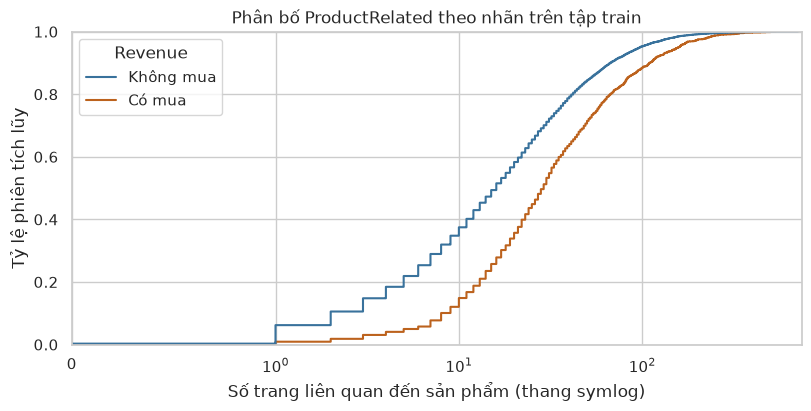

In [4]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
sns.ecdfplot(data=train, x="ProductRelated", hue="KetQua",
             hue_order=label_order, palette=palette, ax=ax)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(left=0)
ax.get_legend().set_title("Revenue")
ax.set(title="Phân bố ProductRelated theo nhãn trên tập train",
       xlabel="Số trang liên quan đến sản phẩm (thang symlog)",
       ylabel="Tỷ lệ phiên tích lũy")
plt.show()

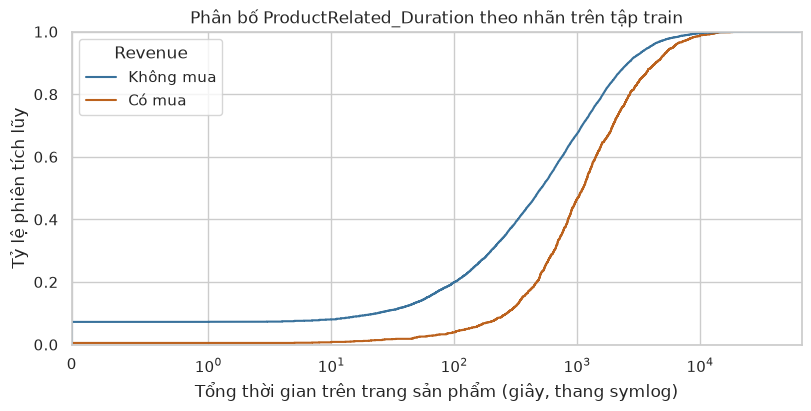

In [5]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
sns.ecdfplot(data=train, x="ProductRelated_Duration", hue="KetQua",
             hue_order=label_order, palette=palette, ax=ax)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(left=0)
ax.get_legend().set_title("Revenue")
ax.set(title="Phân bố ProductRelated_Duration theo nhãn trên tập train",
       xlabel="Tổng thời gian trên trang sản phẩm (giây, thang symlog)",
       ylabel="Tỷ lệ phiên tích lũy")
plt.show()

## 4. Nhận xét từ tập train

In [6]:
grouped = train.groupby("Revenue")
pages = grouped["ProductRelated"].median()
duration = grouped["ProductRelated_Duration"].median()
quartiles = grouped["ProductRelated"].quantile([0.25, 0.75]).unstack()

display(Markdown(f'''
1. **Nhãn mất cân bằng.** Có {y_train.sum():,} phiên mua ({y_train.mean():.2%}) và {(~y_train).sum():,} phiên không mua ({1 - y_train.mean():.2%}).
2. **Số trang sản phẩm.** Trung vị ở nhóm mua là {pages.loc[True]:g} trang, cao hơn mức {pages.loc[False]:g} trang ở nhóm không mua.
3. **Thời gian trên trang sản phẩm.** Trung vị ở nhóm mua là {duration.loc[True]:,.1f} giây, cao hơn mức {duration.loc[False]:,.1f} giây ở nhóm không mua.
4. **Phân bố số trang chồng lấn.** Khoảng phân vị 25%–75% là {quartiles.loc[True, 0.25]:g}–{quartiles.loc[True, 0.75]:g} trang ở nhóm mua và {quartiles.loc[False, 0.25]:g}–{quartiles.loc[False, 0.75]:g} trang ở nhóm không mua. Cả hai nhóm đều có phiên trong khoảng giao nhau.
'''))


1. **Nhãn mất cân bằng.** Có 1,526 phiên mua (15.47%) và 8,338 phiên không mua (84.53%).
2. **Số trang sản phẩm.** Trung vị ở nhóm mua là 29 trang, cao hơn mức 16 trang ở nhóm không mua.
3. **Thời gian trên trang sản phẩm.** Trung vị ở nhóm mua là 1,120.8 giây, cao hơn mức 511.3 giây ở nhóm không mua.
4. **Phân bố số trang chồng lấn.** Khoảng phân vị 25%–75% là 15–57 trang ở nhóm mua và 6–35 trang ở nhóm không mua. Cả hai nhóm đều có phiên trong khoảng giao nhau.
